# 4. 주파수 영역 처리

사진을 여러 방향과 빠르기의 밝기 변화로 나누고, 원하는 성분을 조절한 뒤 다시 영상으로 합친다. 레나 영상과 교육용 줄무늬로 **주파수의 의미와 필터 효과**를 확인한다.

## 4.1 DFT와 FFT

### 공간과 주파수는 같은 영상을 보는 두 가지 방식

- 공간 영역: 어느 위치에 어떤 밝기가 있는지 본다.
- 주파수 영역: 어떤 방향과 빠르기의 밝기 변화가 들어 있는지 본다.
- 넓고 완만한 변화는 저주파, 촘촘한 무늬와 급격한 변화는 고주파 성분과 관련된다.
- 고주파에는 잡음뿐 아니라 중요한 경계도 들어 있다.
- 음악을 여러 음으로 나누듯 영상을 여러 파동 성분으로 나타낸다고 생각하면 된다.

| 용어 | 뜻 | 역할 |
| :---: | :---: | :---: |
| DFT | Discrete Fourier Transform | 이산 푸리에 변환의 정의 |
| FFT | Fast Fourier Transform | DFT를 빠르게 계산하는 알고리즘 계열 |
| IDFT | Inverse DFT | 공간 영상으로 복원 |
| IFFT | Inverse FFT | 역변환을 빠르게 계산 |

FFT가 DFT보다 정확도가 떨어지는 별도 근사 변환이라는 뜻은 아니다. 수치 계산에서는 부동소수점 오차가 생긴다.

### 2차원 DFT 수식

높이 $H$, 너비 $W$인 영상 $f[y,x]$에 대해:

$$
F[v,u]=\sum_{y=0}^{H-1}\sum_{x=0}^{W-1}f[y,x]
\exp\left[-j2\pi\left(\frac{ux}{W}+\frac{vy}{H}\right)\right]
$$

- $x,y$: 공간 좌표, $u,v$: 주파수 인덱스
- $j$: 제곱하면 −1인 허수 단위
- 배열은 `[행, 열]` 순서다.
- $F[0,0]$은 DC 성분이며, 기본 정규화에서 모든 픽셀 값의 합이다.

$$
\overline f=\frac{F[0,0]}{HW}
$$



이 실습은 Gray를 사용한다. 컬러 `(H,W,3)` 배열에 기본 `fft2()`를 바로 적용하면 의도한 공간 축이 아닌 마지막 두 축을 변환하므로 채널별로 처리하거나 공간 축을 명시해야 한다.

OpenCV: 5.0.0 영상 크기: (250, 250)
평균 밝기: 123.550496 DC / 픽셀 수: 123.550496


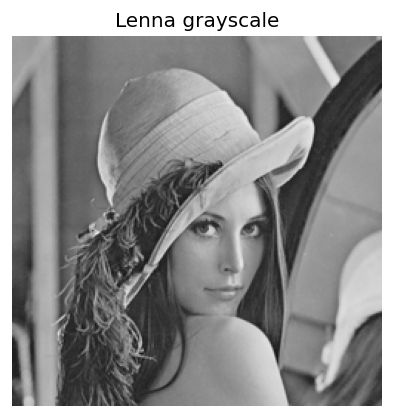

In [1]:
# 셀 1: DFT 계산과 DC 성분
# FFT로 복소 계수를 계산하고 DC를 픽셀 수로 나눈 값이 평균 밝기인지 확인한다.

# Path는 운영체제에 맞게 파일 경로를 조합하는 데 사용한다.
from pathlib import Path
import json
# OpenCV는 영상 처리, NumPy는 배열 계산, Matplotlib은 결과 시각화에 사용한다.
import cv2
import numpy as np
import matplotlib.pyplot as plt
# 현재 작업 폴더를 기준으로 assets를 찾는다. 노트북은 각 장의 폴더에서 실행한다.
ROOT=Path.cwd()  # 노트북과 assets 폴더가 있는 위치
OUT=ROOT/'assets'
# 파일을 바이트 배열로 읽어 디코딩한다. IMREAD_COLOR의 결과는 BGR 순서다.
bgr=cv2.imdecode(np.fromfile(OUT/'Lenna.png',np.uint8),cv2.IMREAD_COLOR)
if bgr is None: raise FileNotFoundError('assets/Lenna.png를 확인하세요.')
# B·G·R을 밝기 가중합으로 바꾸어 단일 채널 영상으로 만든다.
f=cv2.cvtColor(bgr,cv2.COLOR_BGR2GRAY).astype(np.float64)

# 공간 영상을 복소수 주파수 계수로 변환한다. 기본 FFT는 정방향 스케일을 나누지 않는다.
F=np.fft.fft2(f)
print('OpenCV:',cv2.__version__,'영상 크기:',f.shape)
print('평균 밝기:',f.mean(),'DC / 픽셀 수:',F[0,0].real/f.size)
assert np.isclose(F[0,0].real,f.sum())
plt.figure(figsize=(4,4))
plt.imshow(f,cmap='gray',vmin=0,vmax=255)
plt.title('Lenna grayscale')
plt.axis('off')
plt.show()

### 줄무늬로 공간 주파수 이해하기

- 밝기 변화가 한 픽셀마다 얼마나 자주 반복되는지를 cycles/pixel로 나타낸다.
- 아래 세로 줄무늬는 가로 방향으로 밝기가 바뀐다. 따라서 스펙트럼의 봉우리도 가로축 방향에 나타난다.
- 평균 밝기를 뺀 뒤 변환하여 DC를 제거했다. 좌우 두 봉우리는 실수 코사인파의 양·음 주파수 성분이다.

4 회 반복: 봉우리 [-0.03125, 0.03125]
16 회 반복: 봉우리 [-0.125, 0.125]


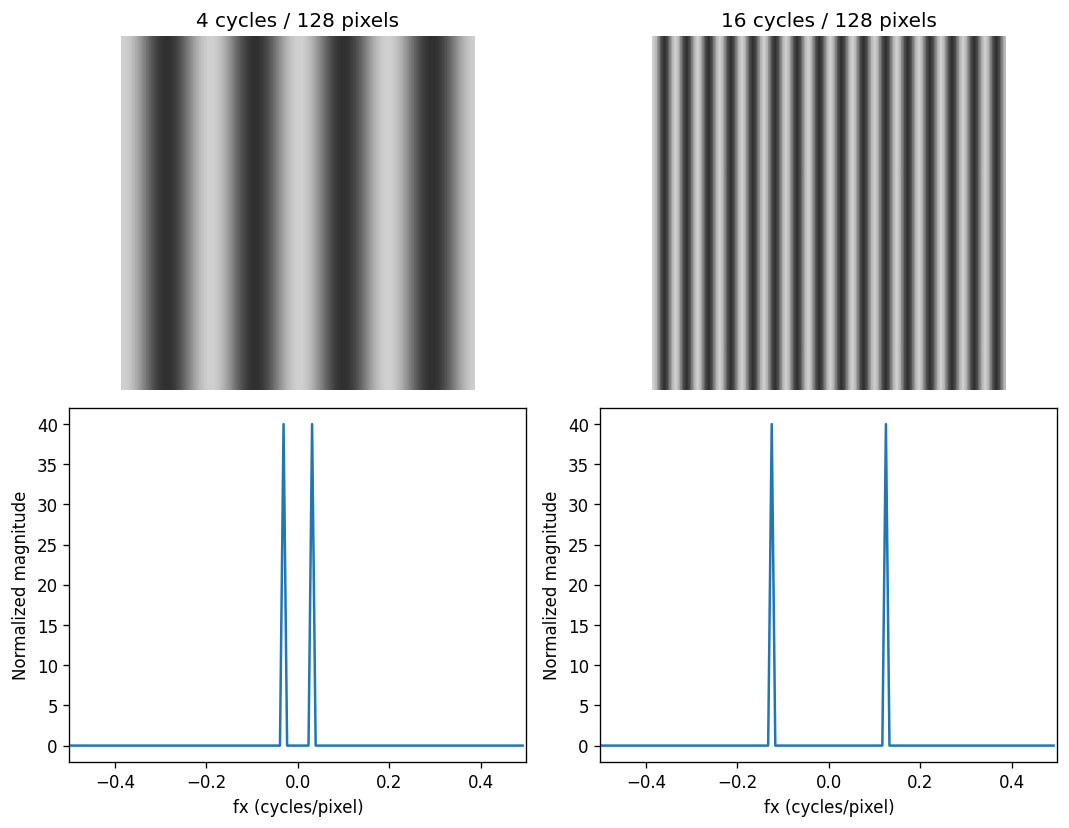

In [2]:
# 셀 2: 줄무늬의 공간 주파수
# 128픽셀 동안 4회와 16회 반복하는 코사인파의 주파수 위치를 비교한다.

n=128
x=np.arange(n)
fig,axs=plt.subplots(2,2,figsize=(9,7))
for i,k in enumerate([4,16]):
    stripes=np.tile(128+80*np.cos(2*np.pi*k*x/n),(n,1))
    S=np.fft.fftshift(np.fft.fft2(stripes-128))
    axs[0,i].imshow(stripes,cmap='gray',vmin=0,vmax=255)
    axs[0,i].set_title(f'{k} cycles / 128 pixels')
    axs[0,i].axis('off')
    freq=np.fft.fftshift(np.fft.fftfreq(n))
    axs[1,i].plot(freq,np.abs(S[n//2])/n**2)
    axs[1,i].set(xlabel='fx (cycles/pixel)',ylabel='Normalized magnitude',xlim=(-0.5,0.5))
    peaks=np.sort(freq[np.argsort(np.abs(S[n//2]))[-2:]])
    assert np.allclose(peaks,[-k/n,k/n])
    print(k,'회 반복: 봉우리',peaks.tolist())
fig.tight_layout()
plt.show()

## 4.2 크기 스펙트럼과 위상

복소 계수에는 크기와 위상이 함께 들어 있다.

$$
F=a+jb=Ae^{j\phi},\qquad
A=\sqrt{a^2+b^2},\quad \phi=\operatorname{atan2}(b,a)
$$

| 정보 | 코드 | 쉬운 뜻 |
| :---: | :---: | :---: |
| 크기 | `np.abs(F)` | 각 성분이 얼마나 들어 있는가 |
| 위상 | `np.angle(F)` | 각 파동의 상대적인 위치 |
| 크기 제곱 | `np.abs(F)**2` | 비정규화 파워 스펙트럼 |

크기가 0인 성분의 위상은 의미가 없고, 매우 작은 성분의 위상 해석도 주의한다.

### 로그 표시

큰 성분에 작은 성분이 묻히지 않도록 표시할 때만 로그를 취한다.

$$
S=\log(1+|F|)
$$



> [!warning] 표시용 그림과 계산 배열 구분
> 로그 스펙트럼 PNG만으로 원본을 복원할 수 없다. 역변환에는 원래 복소 배열을 사용한다. 제공된 `frequency_arrays.npz`에는 복소 스펙트럼과 필터 결과를 보존했다.

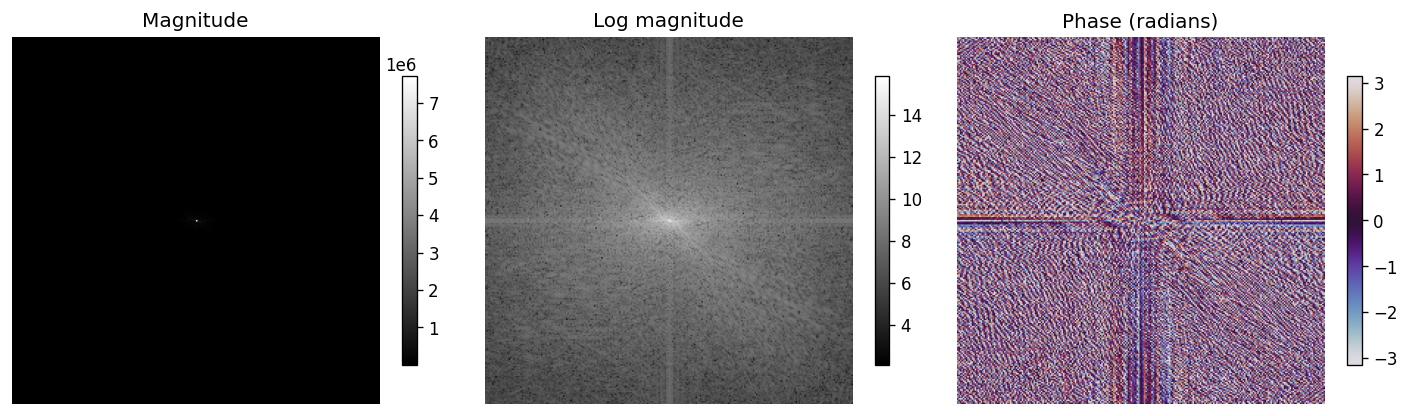

In [3]:
# 셀 3: 크기와 위상 표시
# 크기에는 log1p를 적용해 작은 성분도 보이게 하고, 위상은 라디안으로 표시한다.

# DC가 중앙에 오도록 배열 위치만 재배치한다. 주파수 값 자체를 새로 계산하지 않는다.
Fs=np.fft.fftshift(F)
magnitude=np.abs(Fs)
phase=np.angle(Fs)
fig,axs=plt.subplots(1,3,figsize=(12,4))
for ax,a,title,cmap in zip(axs,[magnitude,np.log1p(magnitude),phase],
                         ['Magnitude','Log magnitude','Phase (radians)'],['gray','gray','twilight']):
    im=ax.imshow(a,cmap=cmap,**({'vmin':-np.pi,'vmax':np.pi} if title.startswith('Phase') else {}))
    ax.set_title(title)
    ax.axis('off')
    fig.colorbar(im,ax=ax,shrink=.65)
fig.tight_layout()
plt.show()

### 위상은 왜 필요한가?



- 오른쪽 영상은 원본을 오른쪽으로 30픽셀 순환 이동한 것이다.
- 밖으로 나간 부분은 반대편으로 돌아온다.
- 두 영상의 크기 스펙트럼은 같지만 위상은 달라진다. 실습에서 수치적으로 확인한다.
- 따라서 크기만으로 물체의 위치를 모두 알 수 없다.

순환 이동 전후 크기 최대 차이: 1.1641532182693481e-10
위상 변화 관계 검증 통과


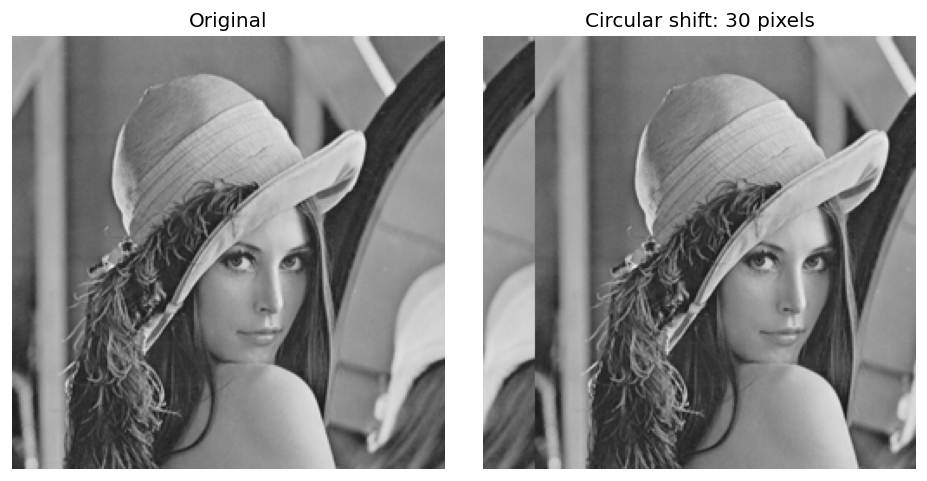

In [4]:
# 셀 4: 순환 이동과 위상
# 오른쪽으로 30픽셀 이동하면 크기 스펙트럼은 유지되고 위상 관계가 달라진다.

shift=np.roll(f,30,axis=1)
assert np.allclose(abs(np.fft.fft2(shift)),abs(F),atol=1e-7)
fig,axs=plt.subplots(1,2,figsize=(8,4))
for ax,a,title in zip(axs,[f,shift],['Original','Circular shift: 30 pixels']):
    ax.imshow(a,cmap='gray',vmin=0,vmax=255);ax.set_title(title);ax.axis('off')
fig.tight_layout();plt.show()


F_shift=np.fft.fft2(shift)
print('순환 이동 전후 크기 최대 차이:',float(np.abs(np.abs(F_shift)-np.abs(F)).max()))
# 순환 이동 정리: 가로 30픽셀 이동은 주파수별 위상 변화를 만든다.
phase_factor=np.exp(-2j*np.pi*np.fft.fftfreq(f.shape[1])*30)
assert np.allclose(F_shift,F*phase_factor[None,:],atol=1e-7)
print('위상 변화 관계 검증 통과')

## 4.3 fftshift와 역변환

### fftshift는 배열 재배치

- 기본 FFT 결과에서 DC는 `[0, 0]`에 있다.
- `fftshift()`는 DC를 중앙에 배치해 보기 쉽게 한다.
- 새로운 변환을 계산하거나 필터링하는 함수는 아니다.
- 중앙 근처는 낮은 주파수이며, 멀수록 높은 주파수다.
- 주파수 방향은 밝기가 변화하는 방향이다. 세로 줄무늬는 가로 주파수에 반응한다.



홀수 크기에서도 올바르게 복원하려면 `fftshift()`와 `ifftshift()`를 짝으로 사용한다.

### 역변환 수식

$$
f[y,x]=\frac{1}{HW}\sum_{v=0}^{H-1}\sum_{u=0}^{W-1}F[v,u]
\exp\left[j2\pi\left(\frac{ux}{W}+\frac{vy}{H}\right)\right]
$$

NumPy 기본 설정은 역변환에서 $1/(HW)$를 적용한다. 수정하지 않은 계수는 원본을 반올림 오차 범위에서 복원한다.



- 위: 원본, 이동 전 로그 크기, 이동 후 로그 크기
- 아래: 위상, 역변환 영상, 절대 복원 오차
- 오차 그림은 아주 작은 값을 확대해 보이는 별도 색 범위다. 큰 영상 손상이 생긴 것이 아니다.

역변환 최대 오차: 1.1368683772161603e-13
최대 허수 잔차: 6.188987108954897e-14


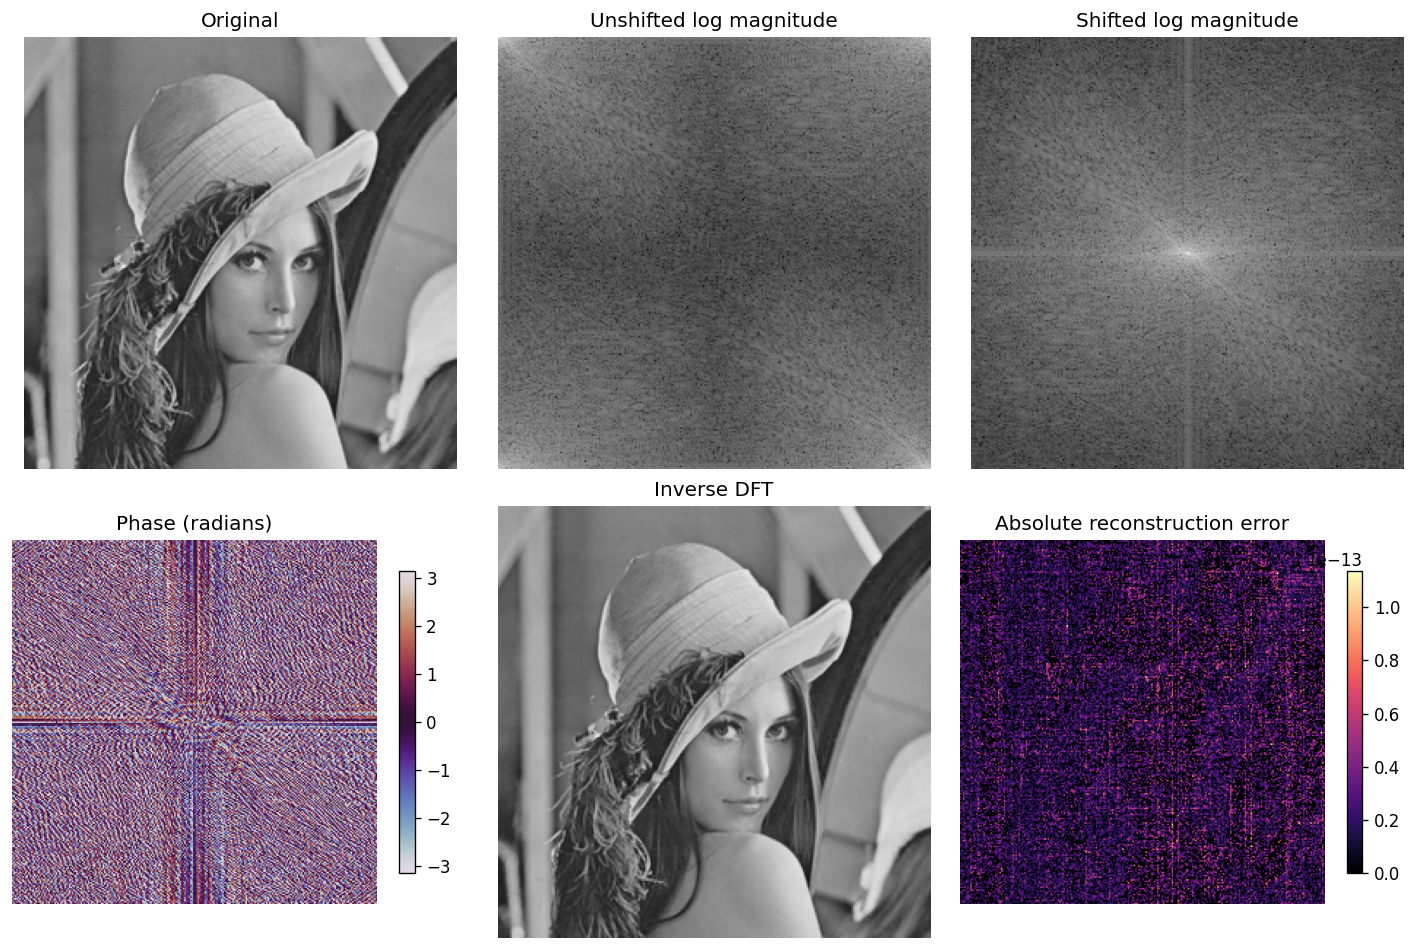

In [5]:
# 셀 5: fftshift 해제와 역변환
# ifftshift로 원래 순서를 복구한 후 역변환하며 실수부 오차와 허수 잔차를 확인한다.

# ifftshift로 배열 순서를 되돌린 뒤 역변환한다. NumPy는 역변환에서 픽셀 수로 나눈다.
rest=np.fft.ifft2(np.fft.ifftshift(Fs))
err=float(np.abs(rest.real-f).max())
assert err<1e-9 and np.abs(rest.imag).max()<1e-9
# 홀수 크기에서는 두 번 fftshift 하는 것으로 역이동을 대신할 수 없다.
odd=f[:249,:247]
odd_back=np.fft.ifft2(np.fft.ifftshift(np.fft.fftshift(np.fft.fft2(odd))))
assert np.max(np.abs(odd_back-odd))<1e-9
print('역변환 최대 오차:',err)
print('최대 허수 잔차:',float(np.abs(rest.imag).max()))
fig,axs=plt.subplots(2,3,figsize=(12,8))
for ax,title,a,cmap in zip(axs.flat,['Original','Unshifted log magnitude','Shifted log magnitude','Phase (radians)','Inverse DFT','Absolute reconstruction error'],[f,np.log1p(abs(F)),np.log1p(abs(Fs)),np.angle(Fs),rest.real,abs(rest.real-f)],['gray','gray','gray','twilight','gray','magma']):
    kwargs={'vmin':0,'vmax':255} if title in ['Original','Inverse DFT'] else {}
    im=ax.imshow(a,cmap=cmap,**kwargs)
    ax.set_title(title)
    ax.axis('off')
    if title in ['Phase (radians)','Absolute reconstruction error']:
        fig.colorbar(im,ax=ax,shrink=.7)
fig.tight_layout()
plt.show()

### OpenCV와 비교



| 항목 | NumPy | OpenCV의 이 설정 |
| :---: | :---: | :---: |
| 복소 배열 | `(H,W)` complex | `(H,W,2)` 실수부·허수부 |
| 역변환 스케일 | 기본 적용 | `DFT_SCALE` 명시 |
| 공간 축 이동 | `fftshift(F)` | `fftshift(cvF, axes=(0,1))` |

실수 출력은 실수 영상에 대응하는 켤레 대칭 계수를 전제로 한다. 임의의 비대칭 마스크를 쓴 뒤 허수부를 무조건 버리지 않는다.

In [6]:
# 셀 6: NumPy와 OpenCV DFT 비교
# OpenCV의 실수부·허수부 2채널을 복소 배열로 조합하고 역변환 스케일을 맞춘다.

# DFT_COMPLEX_OUTPUT을 지정해 실수부·허수부 두 채널을 얻는다.
cvF=cv2.dft(f,flags=cv2.DFT_COMPLEX_OUTPUT)
cv_complex=cvF[:,:,0]+1j*cvF[:,:,1]
assert np.allclose(F,cv_complex,atol=1e-7)
# DFT_SCALE로 역변환 정규화를 적용하고 켤레 대칭 계수에서 실수 출력을 얻는다.
cvback=cv2.idft(cvF,flags=cv2.DFT_SCALE|cv2.DFT_REAL_OUTPUT)
assert np.max(np.abs(cvback-f))<1e-9
print('NumPy shape:',F.shape,'OpenCV shape:',cvF.shape)
print('변환 계수 최대 차이:',float(np.abs(F-cv_complex).max()))
print('OpenCV 역변환 최대 오차:',float(np.abs(cvback-f).max()))

NumPy shape: (250, 250) OpenCV shape: (250, 250, 2)
변환 계수 최대 차이: 3.841815860489176e-10
OpenCV 역변환 최대 오차: 1.5631940186722204e-13


## 4.4 주파수 영역 필터링

### 공통 원리

$$
G[v,u]=M[v,u]F[v,u],\qquad g=\operatorname{IDFT}(G)
$$

- $M$은 각 주파수 성분에 곱할 필터 이득이다.
- 1은 유지, 0은 제거, 0과 1 사이는 약화다.
- 표시용 크기 그림이 아니라 **복소 계수에 마스크를 곱한다**.
- 이동한 스펙트럼에는 이동한 좌표의 마스크를 맞춘다.

### 주파수 좌표를 정확하게 만들기



$$
\rho=\sqrt{f_x^2+f_y^2}
$$

- 단위는 cycles/pixel이다. 예를 들어 한 방향에서 0.1이면 10픽셀마다 한 번 반복한다.
- 주파수 인덱스와 cycles/pixel은 다르다. 영상 크기가 바뀌어도 같은 단위를 쓰면 비교하기 쉽다.
- 각 축의 나이퀴스트 크기는 0.5 cycles/pixel이다. 2차원 모서리의 반경은 약 0.707까지 가능하다.
- 마스크의 회색 밝기는 이득이며 원본 픽셀의 밝기가 아니다.

### 경계와 링잉

- 패딩 없이 DFT에서 곱하면 주기적 경계를 가진 순환 합성곱으로 해석된다.
- 영상의 왼쪽과 오른쪽 등이 연결되어 경계에 인공적인 변화가 나타날 수 있다.
- 실습은 각 방향으로 **64픽셀 반사 패딩**하고 처리한 뒤 원본 크기로 잘라낸다.
- 패딩은 영향을 줄이는 방법이며 모든 조건에서 경계 효과를 완전히 없앤다는 보장은 없다.
- 0/1로 갑자기 끊는 이상적 마스크는 경계 주변에 물결 같은 링잉을 만들 수 있다. 여기서는 부드러운 가우시안 마스크를 사용한다.
- 일반 창 함수를 곱하면 입력 자체도 변하므로 이번 실습에는 적용하지 않았다.

> [!warning] 역변환 후 절댓값을 무조건 취하지 않기
> 고역·대역 결과의 음수는 정상적인 정보다. 실수 영상과 대칭 마스크를 사용했다면 허수 잔차가 충분히 작은지 확인하고 `.real`을 취한다. 절댓값은 별도의 비선형 처리다.

In [7]:
# 셀 7: 반사 패딩과 주파수 좌표
# 경계 영향을 줄이기 위해 64픽셀 패딩하고 cycles/pixel 좌표를 만든다.

# 반사 패딩 후 주파수 영역에서 처리하고 원본 영역을 잘라냅니다.
pad=64
# 반사 패딩은 반대편 경계가 직접 연결되는 영향을 줄이며, 처리 후 원래 영역만 자른다.
padded=np.pad(f,pad,mode='reflect')
P=np.fft.fftshift(np.fft.fft2(padded))
# shape는 (높이, 너비) 순서다. 좌표 (x, y)로 읽을 때는 배열 인덱스 [y, x]와 구분한다.
h,w=padded.shape
# 세로 주파수 좌표를 cycles/pixel 단위로 만들고 스펙트럼과 같은 순서로 이동한다.
fy=np.fft.fftshift(np.fft.fftfreq(h))
# 가로 주파수 좌표도 동일하게 구성하여 직사각형 영상에서 축 간 단위를 맞춘다.
fx=np.fft.fftshift(np.fft.fftfreq(w))
FX,FY=np.meshgrid(fx,fy);rho=np.hypot(FX,FY)

print('원본 크기:',f.shape,'패딩 후:',padded.shape)
print('가로 주파수 간격:',1/w,'cycles/pixel')

원본 크기: (250, 250) 패딩 후: (378, 378)
가로 주파수 간격: 0.0026455026455026454 cycles/pixel


### 저역 통과 필터 (Low-pass)

$$
M_{LP}(\rho)=\exp\left(-\frac{\rho^2}{2s^2}\right)
$$

- 완만한 변화는 남기고 미세한 변화를 줄인다.
- 영상이 부드러워지지만 경계도 흐려질 수 있다.
- 여기서 $s$는 **주파수 영역 폭**이다. 공간 가우시안의 픽셀 단위 $\sigma$와 구분한다.
- $s$가 작을수록 좁은 저주파만 통과시켜 더 많이 흐려진다.
- $s$는 딱 끊기는 차단 주파수가 아니다. $\rho=s$에서 이득은 약 0.607이다.

### 고역 통과 필터 (High-pass)

$$
M_{HP}(\rho)=1-M_{LP}(\rho)
$$

- DC와 완만한 변화를 줄여 경계·질감에 반응한다.
- 출력에 음수가 생기므로 원본처럼 0~255로만 표시하면 정보가 잘린다.
- 고역 통과 결과 자체는 일반적인 샤프닝 완성 영상이 아니다.
- 원본에 고역 결과를 일정 비율로 더하면 샤프닝으로 활용할 수 있다.

$$
g_{\mathrm{sharp}}=f+\alpha g_{HP}
$$

### 대역 통과 필터 (Band-pass)

실습에서는 폭이 다른 두 저역 통과 마스크의 차이를 사용한다.

$$
M_{BP}(\rho)=\exp\left(-\frac{\rho^2}{2s_h^2}\right)-\exp\left(-\frac{\rho^2}{2s_l^2}\right),\qquad 0<s_l<s_h
$$

- 낮은 주파수와 높은 주파수를 줄이고 중간 규모의 변화를 남긴다.
- 실습은 $s_l=0.03$, $s_h=0.12$다.
- 두 값은 부드러운 응답의 폭 설정이며, 그 사이만 완벽하게 통과하는 경계가 아니다.
- 공간 영역의 DoG와 연결되는 가우시안 차분 방식이다. 공간 폭과 주파수 폭은 반대 방향으로 대응한다.



곡선은 반경 0~0.5만 보여주며, 2차원 마스크는 모서리 주파수까지 계산한다.



- 위: 같은 0~1 범위로 표시한 마스크다.
- 아래 왼쪽: 저역 결과, 0~255로 표시했다.
- 아래 가운데·오른쪽: 고역·대역 결과이며 각각 독립된 대칭 색 범위를 사용한다.
- 색 막대를 보고 양수·음수의 크기를 해석한다. 서로 다른 패널의 같은 색이 같은 수치를 뜻하지는 않는다.

필터 결과 최대 허수 잔차: 5.3474322909824486e-14
LP + HP 복원 최대 오차: 1.9895196601282805e-13
Gaussian LP: s=0.06 범위: 43.702149456853526 213.5890052861948
Gaussian HP: s=0.06 범위: -112.07452174139522 111.47326779989515
Gaussian BP: 0.03 / 0.12 범위: -82.88549861295577 82.33621439521673


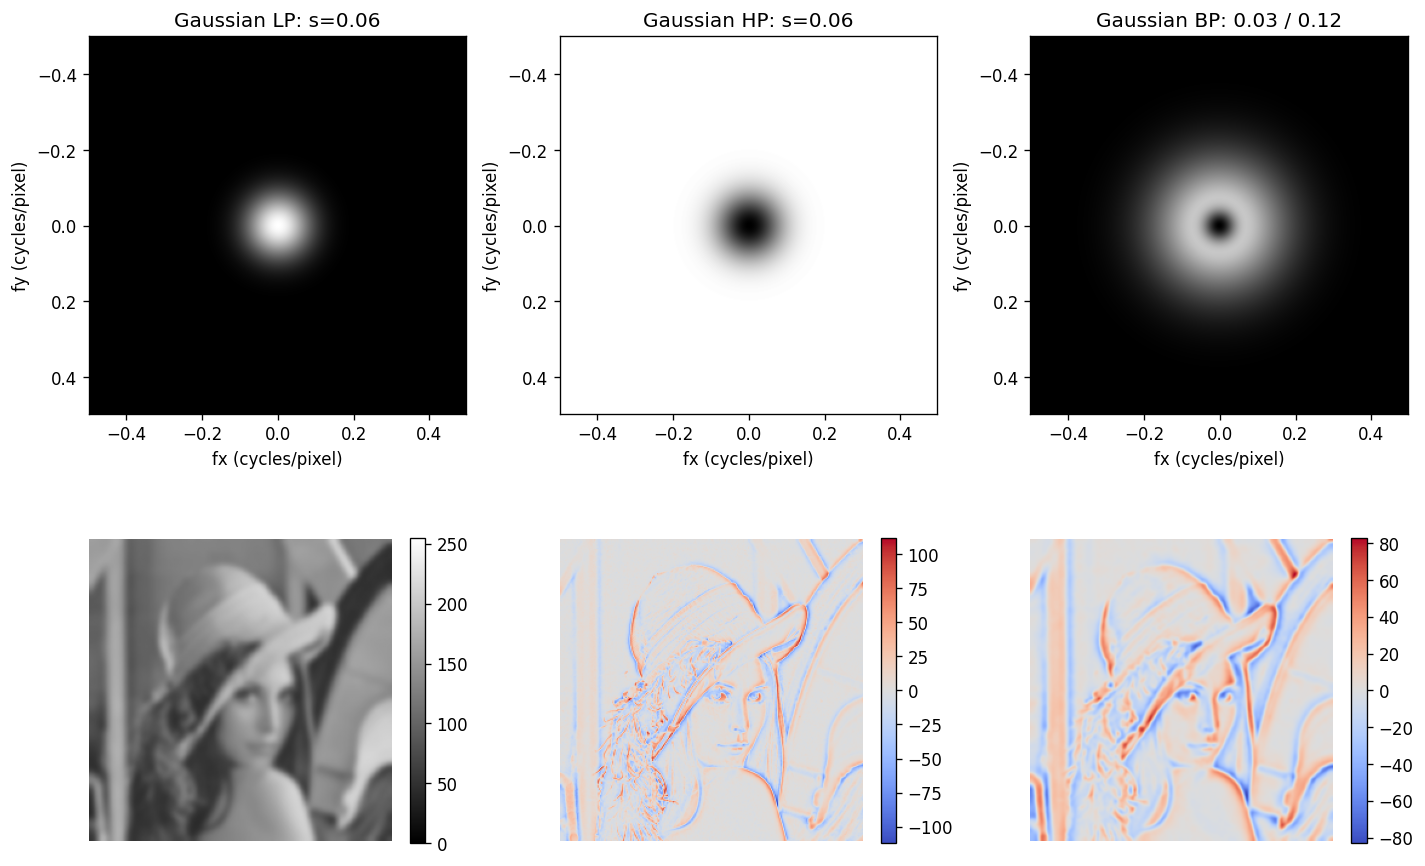

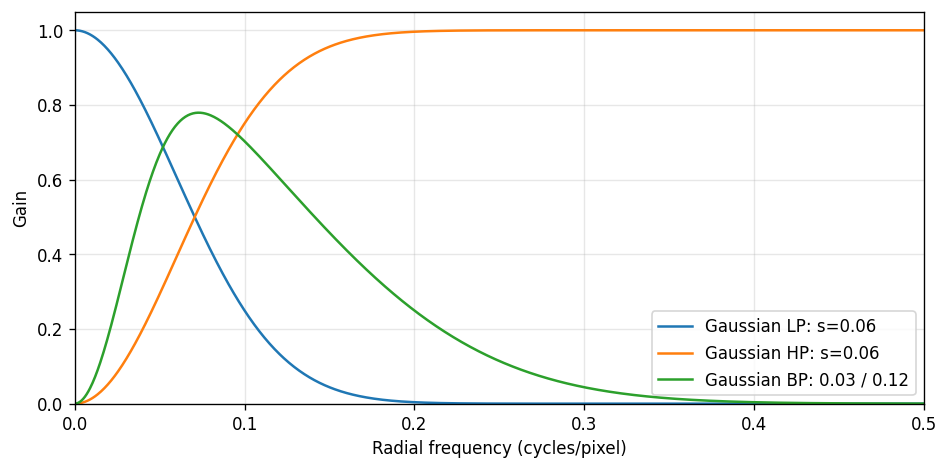

In [8]:
# 셀 8: 저역·고역·대역 통과 필터
# 복소 스펙트럼에 마스크를 곱하고 역변환한다. 고역·대역 결과의 음수를 유지한다.

cut=.06; lo=.03; hi=.12
# 중심 저주파는 유지하고 멀어질수록 감쇠시키며, hp=1-lp로 보완 고역을 만든다.
lp=np.exp(-rho**2/(2*cut**2)); hp=1-lp
# 폭이 넓은 저역 마스크에서 좁은 저역 마스크를 빼 부드러운 대역 통과를 만든다.
bp=np.exp(-rho**2/(2*hi**2))-np.exp(-rho**2/(2*lo**2))
masks=[lp,hp,bp]; names=['Gaussian LP: s=0.06','Gaussian HP: s=0.06','Gaussian BP: 0.03 / 0.12']
outputs=[];residual=[]
for mask in masks:
    # 표시용 크기 그림이 아닌 복소 스펙트럼에 마스크를 곱하여 역변환한다.
    z=np.fft.ifft2(np.fft.ifftshift(P*mask))
    residual.append(float(abs(z.imag).max())); assert residual[-1]<1e-9
    # 반사 패딩을 제외하고 입력과 같은 크기로 결과를 자른다.
    outputs.append(z.real[pad:pad+f.shape[0],pad:pad+f.shape[1]])
assert np.max(abs(outputs[0]+outputs[1]-f))<1e-9
fig,axs=plt.subplots(2,3,figsize=(12,8))
for i,(name,mask,out) in enumerate(zip(names,masks,outputs)):
    im=axs[0,i].imshow(mask,cmap='gray',vmin=0,vmax=1,extent=[fx[0],fx[-1],fy[-1],fy[0]])
    axs[0,i].set_title(name);axs[0,i].set_xlabel('fx (cycles/pixel)');axs[0,i].set_ylabel('fy (cycles/pixel)')
    if i==0: im=axs[1,i].imshow(out,cmap='gray',vmin=0,vmax=255)
    else:
        m=abs(out).max();im=axs[1,i].imshow(out,cmap='coolwarm',vmin=-m,vmax=m)
    axs[1,i].axis('off');fig.colorbar(im,ax=axs[1,i],shrink=.7)
fig.tight_layout();plt.show()
r=np.linspace(0,.5,1000)
fig,ax=plt.subplots(figsize=(8,4))
for a,label in zip([np.exp(-r*r/(2*cut*cut)),1-np.exp(-r*r/(2*cut*cut)),np.exp(-r*r/(2*hi*hi))-np.exp(-r*r/(2*lo*lo))],names):ax.plot(r,a,label=label)
ax.set(xlabel='Radial frequency (cycles/pixel)',ylabel='Gain',ylim=(0,1.05),xlim=(0,.5));ax.legend();ax.grid(alpha=.3)
fig.tight_layout();plt.show()

print('필터 결과 최대 허수 잔차:',max(residual))
print('LP + HP 복원 최대 오차:',float(abs(outputs[0]+outputs[1]-f).max()))
for name,a in zip(names,outputs):
    print(name,'범위:',float(a.min()),float(a.max()))
# 다시 분석할 수 있도록 계산 배열을 원래 자료형으로 보존한다.
np.savez_compressed(ROOT/'frequency_arrays.npz',spectrum=F,lowpass=outputs[0],highpass=outputs[1],bandpass=outputs[2])

### 결과 해석

- 저역 통과 영상에서는 얼굴과 배경의 큰 밝기 변화가 남고 머리카락 같은 세부가 흐려진다.
- 고역·대역 통과는 부호 있는 변화량이다. 음수를 검정으로 잘라내거나 절댓값으로 바꾸면 원래 계산과 달라진다.
- 저역과 보완 고역의 마스크 합은 1이므로, 두 출력의 합이 원본과 일치하는지 확인할 수 있다.
- 마스크 그림의 밝기는 0~1의 **통과 이득**이다. 영상 결과의 0~255 밝기와 구분한다.
- `frequency_arrays.npz`는 시각화용 PNG와 달리 원래 복소 스펙트럼 및 부동소수점 필터 결과를 보존한다.

## 참고 문서

- [NumPy — Discrete Fourier Transform](https://numpy.org/doc/stable/reference/routines.fft.html)
- [OpenCV — Fourier Transform](https://docs.opencv.org/4.x/de/dbc/tutorial_py_fourier_transform.html)

## 실행 검증

OpenCV 5.0.0에서 8개 코드 셀을 같은 Python 실행 상태로 순차 실행하여 출력과 그림을 기록했다. 앞선 실행에서 확인한 Jupyter 커널 통신 권한 제한으로, 이번 검증은 Python 순차 실행으로 진행했다. Jupyter 전체 실행 자체는 검증하지 않았다.